# Floe identification and matching for large-scale images

For the 500 km cases, the number of floes is too large to provide a manual validation dataset. Instead, we tailor the IFT to each case and produce a candidate matching result, which we verify visually.



In [1]:
using Pkg
Pkg.activate("ift-env")

  Activating project at `~/Documents/research/manuscripts/optimal_transport/matchfloes/notebooks/ift-env`


In [44]:
using CairoMakie
using CSV
using DataFrames
using Dates
using IceFloeTracker
using Images

[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0](cache misses: wrong dep version loaded (2), incompatible header (6))
[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0] (cache misses: wrong dep version loaded (4), incompatible header (12))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling CSVFilePathsBaseExt [7d099e6d-d2cf-55c2-939a-b16569e3ddb1]

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of typ

In [23]:
case = "006-baffin_bay-500km-20220530"
dataloc = "../data/"
times = DataFrame(CSV.File(joinpath(dataloc, "overpass_times.csv")))
sort!(times, "pass_time")

# tcase = "166-laptev_sea-500km-20160904.terra.truecolor.250m.tiff"
case_number_title, region, dx, date = split(case, "-")
date_title = Dates.format(Date(date,"yyyymmdd"), "yyyy-mm-dd")
region_title = titlecase(replace(region, "_" => " "))
case_number = parse(Int64, case_number_title)
time_info = subset(times, :case_number => r -> r .== case_number)
satellites = String.(time_info.satellite)
pass_times = DateTime.(time_info.pass_time)

tc_imgs = [load(joinpath(dataloc, case, join([case, sat, "truecolor", "250m", "tiff"], "."))) for sat in satellites]
fc_imgs = [load(joinpath(dataloc, case, join([case, sat, "falsecolor", "250m", "tiff"], "."))) for sat in satellites]
lm_imgs = [load(joinpath(dataloc, case, join([case, sat, "landmask", "250m", "tiff"], "."))) .|> r -> Gray.(r) .> 0 for sat in satellites];

In [28]:
# Preprocessing parameters
diffusion_algorithm = PeronaMalikDiffusion(; λ=0.1, K=0.1, niters=7, g="exponential")
adapthisteq_params = (nbins=256, rblocks=4, cblocks=4, clip=1)
unsharp_mask_params = (radius=50, amount=0.3, threshold=0.01)
tiles = get_tiles(tc_imgs[1], (500,500))
preprocessing_algorithm = FSPipeline.Preprocess(diffusion_algorithm, adapthisteq_params, unsharp_mask_params)

IceFloeTracker.FSPipeline.Preprocess(PeronaMalikDiffusion(0.1, 0.1, 7, "exponential"), (nbins = 256, rblocks = 4, cblocks = 4, clip = 1), (radius = 50, amount = 0.3, threshold = 0.01))

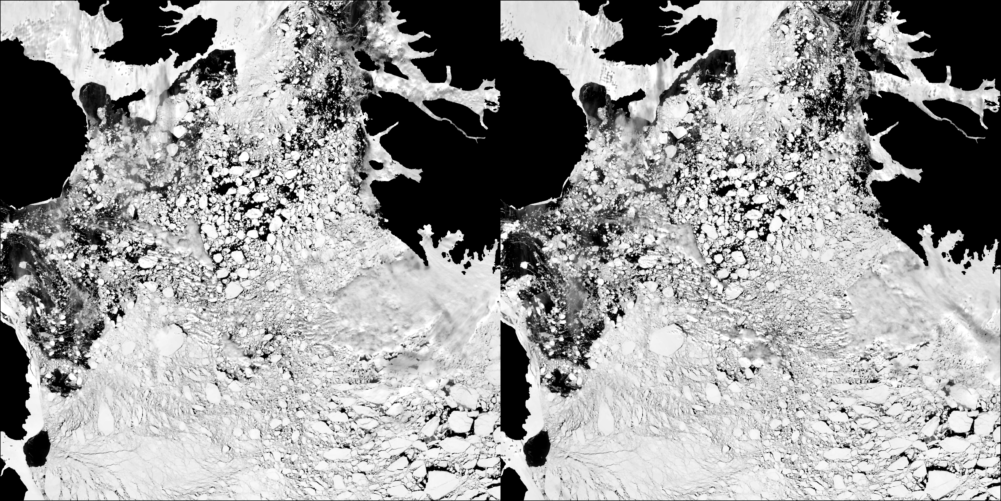

In [122]:
# Demo of enhanced grayscale image
preproc_imgs = preprocessing_algorithm.(tc_imgs, lm_imgs .|> r -> r .> 0, [tiles]);
mosaicview(preproc_imgs..., nrow=1)

In [132]:
# Segmentation parameters
coastal_buffer_structuring_element = strel_disk(12)
cloud_mask_algorithm = Watkins2026CloudMask()
tile_size_pixels = 500
min_tile_ice_pixel_count=300
preliminary_ice_mask = IceDetectionBrightnessMidpoint(; minimum_reflectance=0.3)
kmeans_params = (
    k=4,
    maxiter=50,
    random_seed=45,
    cluster_selection_algorithm=IceDetectionBrightnessPeaksMODIS721(;
        band_7_max=0.1,
        possible_ice_threshold=0.3,
        join_method="union",
        minimum_prominence=0.01,
    ),
)
adaptive_params = (window_size=400, percentage=0)
cleanup_binary_params = (
    erosion_strel=strel_box((3, 3)), init_max_fill=100, conditional_max_fill=500
)
floe_splitting_params = (
    min_floe_size=64,
    max_hole_fill=2000,
    max_depth=25,
    max_depth_ratio=0.7,
    max_expand=3,
    opening_strel=strel_disk(1)
    )
floe_filtering_params = (
    min_floe_size=100,
    min_cloudy_floe_size=1000,
    max_floe_size=50_000,
    min_band_2_reflectance=0.4,
    min_cloudy_band_2_reflectance=0.7,
    cloud_frac_threshold=0.5,
    min_circularity=0.3,
    min_cloudy_circularity=0.5,
)
floe_merging_params = (
    distance_threshold_pixels=10, area_error_threshold=0.25, min_floe_size=100
)

# Initialize segmentation algorithm
segment = FSPipeline.Segment(
    coastal_buffer_structuring_element,
    cloud_mask_algorithm,
    preprocessing_algorithm,
    tile_size_pixels,
    min_tile_ice_pixel_count,
    preliminary_ice_mask,
    kmeans_params,
    adaptive_params,
    cleanup_binary_params,
    floe_splitting_params,
    floe_filtering_params,
    )

IceFloeTracker.FSPipeline.Segment(Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Watkins2026CloudMask(0.15, 0.34, Bool[0 0 … 0 0; 0 1 … 1 0; … ; 0 1 … 1 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 1 … 1 0; … ; 0 1 … 1 0; 0 0 … 0 0], 300, 10000.0, 0.2), IceFloeTracker.FSPipeline.Preprocess(PeronaMalikDiffusion(0.1, 0.1, 7, "exponential"), (nbins = 256, rblocks = 4, cblocks = 4, clip = 1), (radius = 50, amount = 0.3, threshold = 0.01)), 500, 300, IceDetectionBrightnessMidpoint(0.3, 3, 0.01, 128), (k = 4, maxiter = 50, random_seed = 45, cluster_selection_algorithm = IceDetectionBrightnessPeaksMODIS721(0.1, 0.3, 128, 0.01, 3, "union")), (window_size = 400, percentage = 0), (erosion_strel = Bool[1 1 1; 1 1 1; 1 1 1], init_max_fill = 100, conditional_max_fill = 500), (min_floe_size = 64, max_hole_fill = 2000, max_depth = 25, max_depth_ratio = 0.7, max_expand = 3, opening_strel = Bool[0 1 0; 1 1 1; 0 1 0]), (min_floe_size = 100, min_cloudy_floe_size = 1000, max_floe_size = 50000, min_band_2_refle

In [133]:
segmented_imgs = segment.(tc_imgs, fc_imgs, lm_imgs);

[ Info: Building masks
[ Info: Preprocessing truecolor image
[ Info: Binarization
[ Info: Splitting floes
[ Info: Filtering floes
[ Info: Joining segmentation results
[ Info: Building masks
[ Info: Preprocessing truecolor image
[ Info: Binarization
[ Info: Splitting floes
[ Info: Filtering floes
[ Info: Joining segmentation results


In [134]:
labels = labels_map.(segmented_imgs) # extract label matrices

# display segmented image information
segmented_imgs

2-element Vector{SegmentedImage{Matrix{Int64}, RGB{Float64}}}:
 Segmented Image with:
  labels map: 2000×2000 Matrix{Int64}
  number of labels: 1831
 Segmented Image with:
  labels map: 2000×2000 Matrix{Int64}
  number of labels: 1897

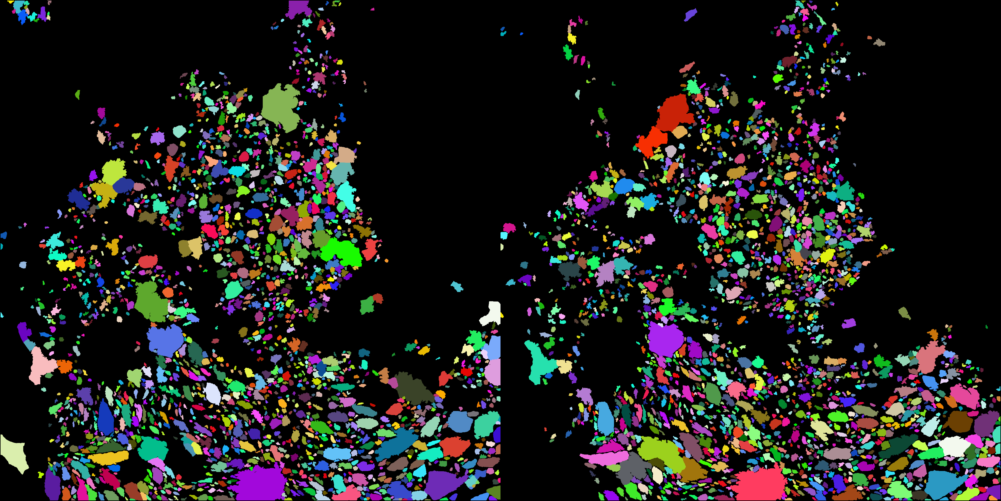

In [135]:
mosaicview(view_seg_random.(segmented_imgs)..., nrow=1)

In [147]:
function assign_labels(img_indexmap, labels_list)
    out = zeros(Int64, size(img_indexmap))
    indices = component_indices(img_indexmap)
    for L in intersect(labels_list, keys(indices))
        out[indices[L]] .= L
    end
    return out
end


assign_labels (generic function with 1 method)

In [159]:
max_travel_distance_filter = DistanceThresholdFilter(;
    threshold_function=LogLogQuadraticTimeDistanceFunction()
)

area_relative_error_filter = RelativeErrorThresholdFilter(;
    variable=:area,
    threshold_function=PiecewiseLinearThresholdFunction(;
        minimum_area=100, maximum_area=700, minimum_value=0.50, maximum_value=0.25
    ),
)

simple_filter = [
    max_travel_distance_filter,
    area_relative_error_filter
]

simple_columns = [
            :scaled_distance,
            :relative_error_area,
        ]
"""
    SimpleTrack()

Track shapes across images using just the LogLogQuadratic distance filter and relative area threshold,
using minimum weight matching.

"""
function SimpleTrack(;
    filter_function=ChainedFilterFunction(; filters=simple_filter),
    matching_function=MinimumWeightMatchingFunction(
        columns=simple_columns,
        weights=ones(2),
    ),
    minimum_area=100, # Minimum floe area for tracking
    maximum_area=90e3, # Maximum floe area for tracking
    maximum_time_step=Day(2), # Maximum length of time to skip
)
    return FloeTracker(;
        filter_function, matching_function, minimum_area, maximum_area, maximum_time_step
    )
end

SimpleTrack

In [165]:
simple_tracker = SimpleTrack()
tracked_floes = simple_tracker(segmented_imgs, pass_times);

l1_tracked = tracked_floes[tracked_floes.passtime .== pass_times[1], :label]
l2_tracked = tracked_floes[tracked_floes.passtime .== pass_times[2], :label];
l1_labels = assign_labels(labels[1], l1_tracked)
l2_labels = assign_labels(labels[2], l2_tracked);

In [168]:
f = Figure(size=(1500, 1500), title=case, figure_padding=10)
n, m = size(tc_imgs[1])
a1 = CairoMakie.Axis(f[1,1], title="True Color Image ("*titlecase(satellites[1])*")")
image!(a1, rotr90(tc_imgs[1]))

# Shuffle labels for a pretty colormap
label_flt = Float64.((labels[1] .% 13) .+ 1)
label_flt[labels[1] .== 0] .= NaN

heatmap!(a1, rotr90(label_flt), colormap=:Paired_12)

# Overlay the label boundaries for the second image
contour!(a1, rotr90(isboundary(l1_labels)), levels=[0.5], color=:blue, linewidth=1)
contour!(a1, rotr90(isboundary(l2_labels)), levels=[0.5], color=:black, linewidth=1)
gdf = groupby(tracked_floes, "ID")
for k in keys(gdf)
    # Note: image coordinates start in upper left, unlike plot coordinates. So we subtract the row from the image height.
    scatterlines!(a1, gdf[k].col_centroid, n .- gdf[k].row_centroid, color=:black, markersize=5)
end
# rowsize!(f.layout, 1, Aspect(1, 1.0))
colsize!(f.layout, 1, Aspect(1, 1.0))

Label(f[0, :], "Case "*case_number_title*", "*region_title*", "*date_title,
    fontsize = 24, font = :bold)

save("../figures/test_large_006_img1_simple_matched.png", f)

f = Figure(size=(1500, 1500), title=case, figure_padding=10)
n, m = size(tc_imgs[1])
a1 = CairoMakie.Axis(f[1,1], title="True Color Image ("*titlecase(satellites[2])*")")
image!(a1, rotr90(tc_imgs[2]))
label_flt = Float64.((labels[2] .% 11) .+ 1)
label_flt[labels[2] .== 0] .= NaN
heatmap!(a1, rotr90(label_flt), colormap=:Paired_12)
contour!(a1, rotr90(isboundary(l1_labels)), levels=[0.5], color=:blue, linewidth=1)
contour!(a1, rotr90(isboundary(l2_labels)), levels=[0.5], color=:black, linewidth=1)
gdf = groupby(tracked_floes, "ID")
for k in keys(gdf)
    # Note: image coordinates start in upper left, unlike plot coordinates. So we subtract the row from the image height.
    scatterlines!(a1, gdf[k].col_centroid, n .- gdf[k].row_centroid, color=:black, markersize=5)
end
# rowsize!(f.layout, 1, Aspect(1, 1.0))
colsize!(f.layout, 1, Aspect(1, 1.0))

Label(f[0, :], "Case "*case_number_title*", "*region_title*", "*date_title,
    fontsize = 24, font = :bold)

save("../figures/test_large_006_img2_simple_matched.png", f)